## 0. Imports and Path Assignments

In [1]:
import sys
sys.path.append("../helper")
from runtime_memory import *
from visualization import * 
from metrics import * 
from pathlib import Path
import os
import pandas as pd
from glob import glob
from warnings import simplefilter
simplefilter("ignore")

In [3]:
data_dir = Path.cwd().parent / "data" / "runtime_memory"
results_dir = Path.cwd() / "results"
log_dir = Path.cwd() / "logs"
pipelines_dir = data_dir / "pipelines"
fig_dir = Path.cwd() / "figures"
os.makedirs(fig_dir, exist_ok = True)

hue_order=["Xengsort", "ICRG", "bamcmp", "XenofilteR"]

## 1. Alignments

In [4]:
alignments = process_nfcore_traces(data_dir)
alignments["sample"] = alignments["sample"].map(sample_map_short)
alignments["realtime_h"] = alignments["realtime_s"] / 3600
alignments["peak_rss_gb"] = alignments["peak_rss_mb"] / 1000


In [5]:
alignments['sample_long'] = alignments['sample'].str.replace(r'M(\d+)', r'Mix \1', regex=True)

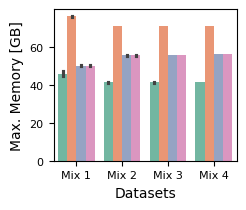

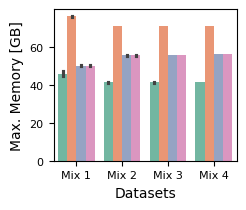

In [7]:
ax, pos = barplot_runmem(alignments, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_alignment_maxmemory.pdf")
ax, pos = barplot_runmem(alignments, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_alignment_maxmemory.png")


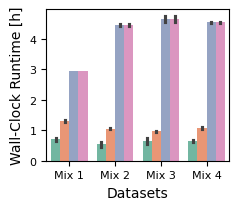

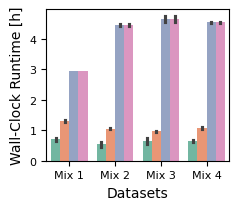

In [8]:
ax, pos = barplot_runmem(alignments, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue = "method", figsize=mm_to_inches((60, 50)), legend=False, hue_order = hue_order, errorbar = "sd",
               save=True, fig_dir=fig_dir, file_name="barplot_alignment_runtime.pdf", xlabel = "Datasets")

ax, pos = barplot_runmem(alignments, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue = "method", figsize=mm_to_inches((60, 50)), legend=False, hue_order = hue_order, errorbar = "sd",
               save=True, fig_dir=fig_dir, file_name="barplot_alignment_runtime.png", xlabel = "Datasets")

## 2. Read sortings

In [9]:
xengsort = parse_lsf_logs(log_dir, method="xengsort", pattern="xengsort_*.out")
xengsort["sample"] = xengsort["sample"].map(sample_map_short1)

bamcmp   = parse_lsf_logs(log_dir, method="bamcmp",   pattern="bamcmp_*.out")
bamcmp["sample"] = bamcmp["sample"].map(sample_map_short1)

xenofilter = parse_lsf_logs(log_dir, method="xenofilter", pattern="xenofilter_*.out")
xenofilter["sample"] = xenofilter["sample"].str.strip().map(sample_map_short1)


In [10]:
sortings = pd.concat([xengsort, bamcmp, xenofilter], ignore_index = True) 
sortings["realtime_h"] = sortings["realtime_s"] / 3600
sortings["peak_rss_gb"] = sortings["peak_rss_mb"] / 1000 # SI units 
sortings["method"] = sortings["method"].map(method_map)
sortings["stage"] = "sorting"
sortings['sample_long'] = sortings['sample'].str.replace(r'M(\d+)', r'Mix \1', regex=True)

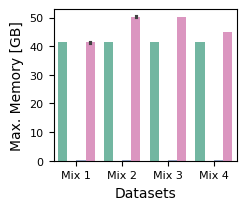

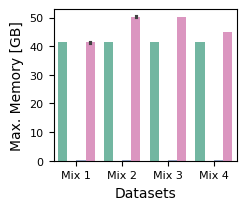

In [12]:
ax, pos = barplot_runmem(sortings, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd",xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_maxmemory.pdf")
ax, pos = barplot_runmem(sortings, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd",xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_maxmemory.png")


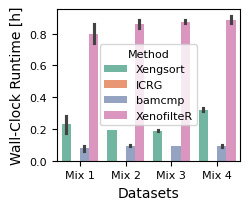

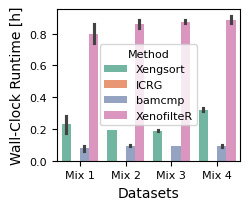

In [13]:
ax, pos = barplot_runmem(sortings, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=True, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_runtime.pdf")

ax, pos = barplot_runmem(sortings, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=True, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_runtime.png")


## 3. Alignment  + Sorting

In [14]:
concat = pd.concat([alignments, sortings], ignore_index = True)

In [15]:
final_df = (
    concat
    .groupby(["sample_long", "method", "replicate"], as_index=False)
    .agg(realtime_s=("realtime_s", "sum"), peak_rss_mb=("peak_rss_mb", "max"))
)
final_df["realtime_h"]  = final_df["realtime_s"] / 3600
final_df["peak_rss_gb"] = final_df["peak_rss_mb"] / 1000


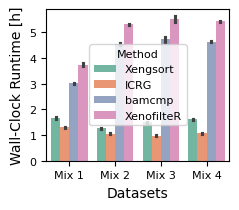

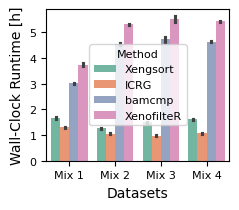

In [16]:
ax, pos = barplot_runmem(final_df, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=True, save=True, fig_dir = fig_dir, file_name = "barplot_final_runtime.pdf")

ax, pos = barplot_runmem(final_df, y="realtime_h", x="sample_long", ylabel="Wall-Clock Runtime [h]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=True, save=True, fig_dir = fig_dir, file_name = "barplot_final_runtime.png")


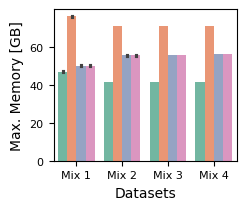

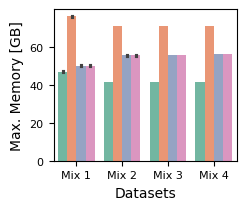

In [17]:
ax, pos = barplot_runmem(final_df, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_final_maxmemory.pdf")

ax, pos = barplot_runmem(final_df, y="peak_rss_gb", x="sample_long", ylabel="Max. Memory [GB]",
               hue="method", hue_order=hue_order, errorbar="sd", xlabel = "Datasets",
               figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir = fig_dir, file_name = "barplot_final_maxmemory.png")


In [18]:
summary_df = (
    final_df
    .groupby("method", as_index=False)
    .agg(realtime_s=("realtime_s", "mean"), peak_rss_mb=("peak_rss_mb", "mean"))
)
summary_df["realtime_h"]  = summary_df["realtime_s"] / 3600
summary_df["peak_rss_gb"] = summary_df["peak_rss_mb"] / 1000


## Save dataframes

In [19]:
sortings.to_csv(results_dir / "sortings.csv")
alignments.to_csv(results_dir / "alignments.csv")
final_df.to_csv(results_dir / "final.csv")
summary_df.to_csv(results_dir /"summary.csv")